# Лабораторная работа 4

Tensorflow 2.x

1) Подготовка данных

2) Использование Keras Model API

3) Использование Keras Sequential + Functional API

https://www.tensorflow.org/tutorials

Для выполнения лабораторной работы необходимо установить tensorflow версии 2.0 или выше .

Рекомендуется использовать возможности Colab'а по обучению моделей на GPU.



In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np
import matplotlib.pyplot as plt
from digits_data import load_variant2
np.random.seed(42)
%matplotlib inline
plt.rcParams['figure.figsize'] = (9, 4)
plt.rcParams['image.cmap'] = 'gray'

os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '3')
os.environ.setdefault('TF_NUM_INTRAOP_THREADS', '1')
os.environ.setdefault('TF_NUM_INTEROP_THREADS', '1')
import tensorflow as tf
import copy
from time import perf_counter
tf.config.threading.set_intra_op_parallelism_threads(1)
tf.config.threading.set_inter_op_parallelism_threads(1)
tf.keras.utils.set_random_seed(42)
print('TensorFlow:', tf.__version__)
device = '/CPU:0'


TensorFlow: 2.21.0


# Подготовка данных
Загрузите набор данных из предыдущей лабораторной работы. 

In [2]:
data = load_variant2(layout='nhwc')
X_train, y_train = data['X_train'].astype('float32'), data['y_train']
X_val, y_val = data['X_val'].astype('float32'), data['y_val']
X_test, y_test = data['X_test'].astype('float32'), data['y_test']
for split in ['train', 'val', 'test']: print(split, data['X_' + split].shape)
input_shape, num_classes = (8, 8, 1), 10


train (1077, 8, 8, 1)
val (360, 8, 8, 1)
test (360, 8, 8, 1)


In [3]:
class Dataset:
    """Мини-батчи NumPy; перемешиваются реальные индексы, включая последний батч."""
    def __init__(self, X, y, batch_size, shuffle=False):
        assert len(X) == len(y)
        self.X, self.y = X, y
        self.batch_size, self.shuffle = batch_size, shuffle

    def __iter__(self):
        indices = np.arange(len(self.y))
        if self.shuffle:
            np.random.shuffle(indices)
        for start in range(0, len(indices), self.batch_size):
            batch = indices[start:start + self.batch_size]
            yield self.X[batch], self.y[batch]

train_dset = Dataset(X_train, y_train, 64, shuffle=True)
val_dset = Dataset(X_val, y_val, 64)
test_dset = Dataset(X_test, y_test, 64)

# tf.data с небольшим пулом потоков для запуска model.fit на CPU.
def tf_dataset(X, y, shuffle=False):
    result = tf.data.Dataset.from_tensor_slices((X, y))
    if shuffle:
        result = result.shuffle(len(y), seed=42, reshuffle_each_iteration=True)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 1
    options.threading.max_intra_op_parallelism = 1
    return result.batch(64).with_options(options)
fit_train = tf_dataset(X_train, y_train, True)
fit_val = tf_dataset(X_val, y_val)
fit_test = tf_dataset(X_test, y_test)


In [4]:
# We can iterate through a dataset like this:
for t, (x, y) in enumerate(train_dset):
    print(t, x.shape, y.shape)
    if t > 5: break

0 (64, 8, 8, 1) (64,)
1 (64, 8, 8, 1) (64,)
2 (64, 8, 8, 1) (64,)
3 (64, 8, 8, 1) (64,)
4 (64, 8, 8, 1) (64,)
5 (64, 8, 8, 1) (64,)
6 (64, 8, 8, 1) (64,)


**Вариант 2.** Используется `sklearn.datasets.load_digits` (1797 цифр 8×8),
указанный в методических материалах под названием MNIST. Это отдельный набор,
не полный MNIST 28×28. Во всех работах одно стратифицированное разбиение
60/20/20 с `random_state=42`. Гиперпараметры выбираются без тестовой выборки.
Интенсивности делятся на 16; среднее для центрирования считается только по train.


#  Keras Model Subclassing API


Для реализации собственной модели с помощью Keras Model Subclassing API необходимо выполнить следующие шаги:

1) Определить новый класс, который является наследником tf.keras.Model.

2) В методе __init__() определить все необходимые слои из модуля tf.keras.layer

3) Реализовать прямой проход в методе call() на основе слоев, объявленных в __init__()

Ниже приведен пример использования keras API для определения двухслойной полносвязной сети. 

https://www.tensorflow.org/versions/r2.0/api_docs/python/tf/keras

In [5]:
class TwoLayerFC(tf.keras.Model):
    def __init__(self, hidden_size, num_classes):
        super().__init__()
        self.flatten = tf.keras.layers.Flatten()
        self.fc1 = tf.keras.layers.Dense(hidden_size, activation='relu', kernel_initializer='he_normal')
        self.fc2 = tf.keras.layers.Dense(num_classes, activation='softmax')

    def call(self, x, training=False):
        return self.fc2(self.fc1(self.flatten(x)))

assert TwoLayerFC(64, 10)(tf.zeros((4, 8, 8, 1))).shape == (4, 10)


Реализуйте трехслойную CNN для вашей задачи классификации. 

Архитектура сети:
    
1. Сверточный слой (5 x 5 kernels, zero-padding = 'same')
2. Функция активации ReLU 
3. Сверточный слой (3 x 3 kernels, zero-padding = 'same')
4. Функция активации ReLU 
5. Полносвязный слой 
6. Функция активации Softmax 

https://www.tensorflow.org/versions/r2.0/api_docs/python/tf/keras/layers/Conv2D

https://www.tensorflow.org/versions/r2.0/api_docs/python/tf/keras/layers/Dense

In [6]:
class ThreeLayerConvNet(tf.keras.Model):
    def __init__(self, channel_1, channel_2, num_classes):
        super().__init__()
        self.conv1 = tf.keras.layers.Conv2D(channel_1, 5, padding='same', activation='relu', kernel_initializer='he_normal')
        self.conv2 = tf.keras.layers.Conv2D(channel_2, 3, padding='same', activation='relu', kernel_initializer='he_normal')
        self.flatten = tf.keras.layers.Flatten()
        self.fc = tf.keras.layers.Dense(num_classes, activation='softmax')

    def call(self, x, training=False):
        return self.fc(self.flatten(self.conv2(self.conv1(x))))


In [7]:
scores = ThreeLayerConvNet(12, 8, 10)(tf.zeros((64, 8, 8, 1)))
assert scores.shape == (64, 10)
np.testing.assert_allclose(tf.reduce_sum(scores, axis=1), 1, atol=1e-6)
print('CNN output:', scores.shape)


CNN output: (64, 10)


Пример реализации процесса обучения:

In [8]:
def evaluate(model, dataset):
    correct, count, loss_sum = 0, 0, 0.0
    for x, y in dataset:
        probabilities = model(x, training=False)
        losses = tf.keras.losses.sparse_categorical_crossentropy(y, probabilities)
        loss_sum += float(tf.reduce_sum(losses))
        correct += int(np.sum(np.argmax(probabilities.numpy(), axis=1) == y))
        count += len(y)
    return loss_sum / count, correct / count


def train_part34(model_init_fn, optimizer_init_fn, num_epochs=1, is_training=True):
    tf.keras.utils.set_random_seed(42)
    model, optimizer = model_init_fn(), optimizer_init_fn()
    model(X_train[:1])
    loss_fn = tf.keras.losses.SparseCategoricalCrossentropy()

    @tf.function(reduce_retracing=True)
    def step(x, y):
        with tf.GradientTape() as tape:
            probabilities = model(x, training=is_training)
            loss = loss_fn(y, probabilities)
            if model.losses:
                loss += tf.add_n(model.losses)
        gradients = tape.gradient(loss, model.trainable_variables)
        optimizer.apply_gradients(zip(gradients, model.trainable_variables))
        return loss

    history = {'loss': [], 'accuracy': [], 'val_loss': [], 'val_accuracy': []}
    best_acc, best_weights = -1, None
    for epoch in range(num_epochs):
        for x, y in train_dset:
            step(tf.convert_to_tensor(x), tf.convert_to_tensor(y))
        train_loss, train_acc = evaluate(model, train_dset)
        val_loss, val_acc = evaluate(model, val_dset)
        for key, value in zip(history, [train_loss, train_acc, val_loss, val_acc]):
            history[key].append(value)
        if val_acc > best_acc:
            best_acc, best_weights = val_acc, model.get_weights()
        print(f'Epoch {epoch + 1}/{num_epochs}: loss={train_loss:.4f}, '
              f'train={train_acc:.4f}, val={val_acc:.4f}')
    model.set_weights(best_weights)
    return model, history


def plot_histories(histories):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3))
    for name, history in histories.items():
        axes[0].plot(history['loss'], label=name)
        axes[1].plot(history['val_accuracy'], label=name)
    axes[0].set_title('Train loss'); axes[1].set_title('Validation accuracy')
    for ax in axes: ax.set_xlabel('Эпоха (индекс с 0)'); ax.legend(fontsize=7)
    plt.tight_layout(); plt.show()


In [9]:
fc_model, fc_history = train_part34(lambda: TwoLayerFC(128, 10),
    lambda: tf.keras.optimizers.SGD(learning_rate=0.1), num_epochs=1)


Epoch 1/1: loss=1.7794, train=0.6249, val=0.6083


Обучите трехслойную CNN. В tf.keras.optimizers.SGD укажите Nesterov momentum = 0.9 . 

https://www.tensorflow.org/versions/r2.0/api_docs/python/tf/optimizers/SGD

Значение accuracy на валидационной выборке после 1 эпохи обучения должно быть > 50% .

In [10]:
learning_rate = 0.05
channel_1, channel_2, num_classes = 32, 16, 10

def model_init_fn():
    return ThreeLayerConvNet(channel_1, channel_2, num_classes)

def optimizer_init_fn():
    return tf.keras.optimizers.SGD(learning_rate=learning_rate, momentum=0.9, nesterov=True)

subclass_model, subclass_history = train_part34(model_init_fn, optimizer_init_fn)
assert subclass_history['val_accuracy'][0] > 0.5


Epoch 1/1: loss=0.1731, train=0.9434, val=0.9472


# Использование Keras Sequential API для реализации последовательных моделей.

Пример для полносвязной сети:

In [11]:
def sequential_fc():
    return tf.keras.Sequential([
        tf.keras.Input(shape=input_shape), tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation='relu', kernel_initializer='he_normal'),
        tf.keras.layers.Dense(10, activation='softmax')])

sequential_fc_model, sequential_fc_history = train_part34(sequential_fc,
    lambda: tf.keras.optimizers.SGD(learning_rate=0.1))


Epoch 1/1: loss=1.7794, train=0.6249, val=0.6083


Альтернативный менее гибкий способ обучения:

In [12]:
model = sequential_fc()
model.compile(optimizer=tf.keras.optimizers.SGD(learning_rate=0.1),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
fc_fit_history = model.fit(fit_train, epochs=1, validation_data=fit_val, shuffle=False, verbose=0).history
print('Sequential FC via fit, val:', fc_fit_history['val_accuracy'][-1])


Sequential FC via fit, val: 0.6166666746139526


Перепишите реализацию трехслойной CNN с помощью tf.keras.Sequential API . Обучите модель двумя способами.

In [13]:
def sequential_cnn():
    return tf.keras.Sequential([
        tf.keras.Input(shape=input_shape),
        tf.keras.layers.Conv2D(32, 5, padding='same', activation='relu', kernel_initializer='he_normal'),
        tf.keras.layers.Conv2D(16, 3, padding='same', activation='relu', kernel_initializer='he_normal'),
        tf.keras.layers.Flatten(), tf.keras.layers.Dense(10, activation='softmax')])

seq_manual_model, seq_manual_history = train_part34(sequential_cnn,
    lambda: tf.keras.optimizers.SGD(learning_rate=0.05, momentum=0.9, nesterov=True))


Epoch 1/1: loss=0.1731, train=0.9434, val=0.9472


Sequential CNN via fit, val: 0.9111111164093018


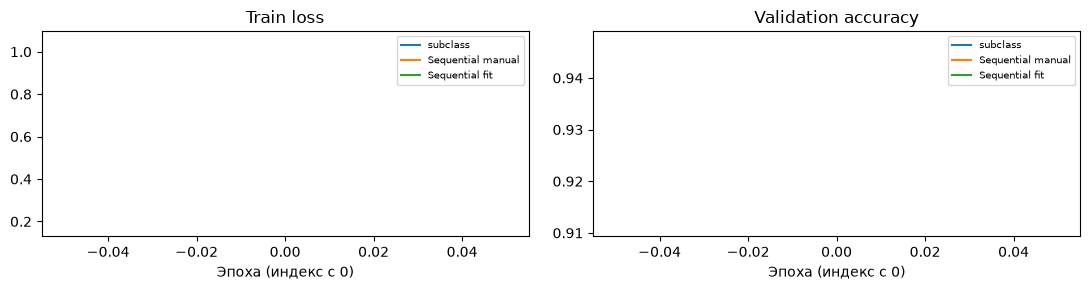

In [14]:
tf.keras.utils.set_random_seed(42)
seq_fit_model = sequential_cnn()
seq_fit_model.compile(optimizer=tf.keras.optimizers.SGD(learning_rate=0.05, momentum=0.9, nesterov=True),
                      loss='sparse_categorical_crossentropy', metrics=['accuracy'])
seq_fit_history = seq_fit_model.fit(fit_train, epochs=1, validation_data=fit_val, shuffle=False, verbose=0).history
print('Sequential CNN via fit, val:', seq_fit_history['val_accuracy'][-1])
plot_histories({'subclass': subclass_history, 'Sequential manual': seq_manual_history,
                'Sequential fit': seq_fit_history})


# Использование Keras Functional API

Для реализации более сложных архитектур сети с несколькими входами/выходами, повторным использованием слоев, "остаточными" связями (residual connections) необходимо явно указать входные и выходные тензоры. 

Ниже представлен пример для полносвязной сети. 

In [15]:
def two_layer_fc_functional(input_shape, hidden_size, num_classes):
    inputs = tf.keras.Input(shape=input_shape)
    x = tf.keras.layers.Flatten()(inputs)
    x = tf.keras.layers.Dense(hidden_size, activation='relu', kernel_initializer='he_normal')(x)
    scores = tf.keras.layers.Dense(num_classes, activation='softmax')(x)
    return tf.keras.Model(inputs=inputs, outputs=scores)

assert two_layer_fc_functional(input_shape, 128, 10)(tf.zeros((4, *input_shape))).shape == (4, 10)

def functional_cnn():
    inputs = tf.keras.Input(shape=input_shape)
    x = tf.keras.layers.Conv2D(32, 5, padding='same', activation='relu', kernel_initializer='he_normal')(inputs)
    x = tf.keras.layers.Conv2D(16, 3, padding='same', activation='relu', kernel_initializer='he_normal')(x)
    x = tf.keras.layers.Flatten()(x)
    outputs = tf.keras.layers.Dense(10, activation='softmax')(x)
    return tf.keras.Model(inputs, outputs)


In [16]:
functional_fc_model, functional_fc_history = train_part34(
    lambda: two_layer_fc_functional(input_shape, 128, 10),
    lambda: tf.keras.optimizers.SGD(learning_rate=0.1))
functional_model, functional_history = train_part34(functional_cnn,
    lambda: tf.keras.optimizers.SGD(learning_rate=0.05, momentum=0.9, nesterov=True))


Epoch 1/1: loss=1.7794, train=0.6249, val=0.6083


Epoch 1/1: loss=0.1731, train=0.9434, val=0.9472


Поэкспериментируйте с архитектурой сверточной сети. Для вашего набора данных вам необходимо получить как минимум 70% accuracy на валидационной выборке за 10 эпох обучения. Опишите все эксперименты и сделайте выводы (без выполнения данного пункта работы приниматься не будут). 

Эспериментируйте с архитектурой, гиперпараметрами, функцией потерь, регуляризацией, методом оптимизации.  

https://www.tensorflow.org/versions/r2.0/api_docs/python/tf/keras/layers/BatchNormalization#methods https://www.tensorflow.org/versions/r2.0/api_docs/python/tf/keras/layers/Dropout#methods

Experiment: Adam 0.001


Epoch 1/10: loss=1.8647, train=0.4800, val=0.4611
Epoch 2/10: loss=1.3321, train=0.7725, val=0.7194
Epoch 3/10: loss=0.8609, train=0.8477, val=0.8028


Epoch 4/10: loss=0.5723, train=0.8923, val=0.8639
Epoch 5/10: loss=0.3984, train=0.9183, val=0.8944
Epoch 6/10: loss=0.3060, train=0.9387, val=0.9056


Epoch 7/10: loss=0.2322, train=0.9471, val=0.9250
Epoch 8/10: loss=0.1930, train=0.9601, val=0.9278
Epoch 9/10: loss=0.1570, train=0.9786, val=0.9389


Epoch 10/10: loss=0.1334, train=0.9786, val=0.9444
max validation accuracy: 0.9444444444444444
Experiment: Adam 0.003


...

Epoch 1/10: loss=1.5132, train=0.7168, val=0.6861
Epoch 2/10: loss=0.8234, train=0.8793, val=0.8472


Epoch 3/10: loss=0.5201, train=0.9174, val=0.8917
Epoch 4/10: loss=0.4096, train=0.9285, val=0.8889


Epoch 5/10: loss=0.2755, train=0.9721, val=0.9333
Epoch 6/10: loss=0.1925, train=0.9824, val=0.9444


Epoch 7/10: loss=0.1362, train=0.9907, val=0.9639
Epoch 8/10: loss=0.1444, train=0.9824, val=0.9444


Epoch 9/10: loss=0.0800, train=0.9954, val=0.9639
Epoch 10/10: loss=0.0733, train=0.9935, val=0.9639
max validation accuracy: 0.9638888888888889


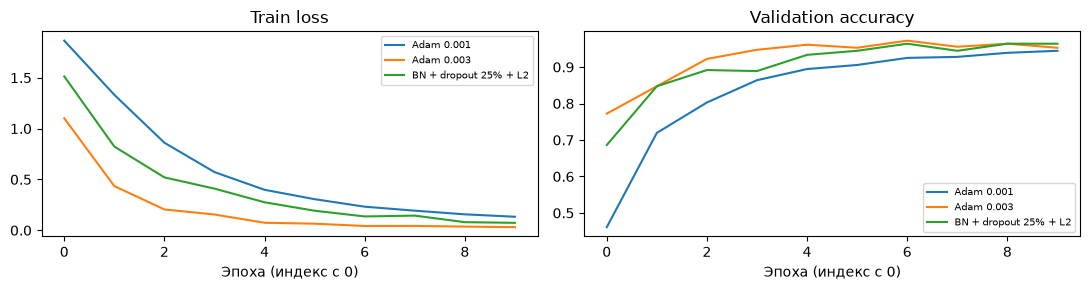

Best: Adam 0.003
Final test: loss=0.1055, accuracy=0.9639
Adam 0.001: first val=0.4611, best val=0.9444, final val=0.9444
Adam 0.003: first val=0.7722, best val=0.9722, final val=0.9528
BN + dropout 25% + L2: first val=0.6861, best val=0.9639, final val=0.9639


In [17]:
class CustomConvNet(tf.keras.Model):
    def __init__(self, use_bn=False, dropout=0.0, reg=0.0):
        super().__init__()
        penalty = tf.keras.regularizers.l2(reg)
        self.conv1 = tf.keras.layers.Conv2D(16, 3, padding='same', kernel_initializer='he_normal', kernel_regularizer=penalty)
        self.conv2 = tf.keras.layers.Conv2D(32, 3, padding='same', kernel_initializer='he_normal', kernel_regularizer=penalty)
        self.bn1 = tf.keras.layers.BatchNormalization() if use_bn else None
        self.bn2 = tf.keras.layers.BatchNormalization() if use_bn else None
        self.pool = tf.keras.layers.MaxPooling2D(2)
        self.flatten = tf.keras.layers.Flatten()
        self.fc = tf.keras.layers.Dense(64, activation='relu', kernel_initializer='he_normal', kernel_regularizer=penalty)
        self.dropout = tf.keras.layers.Dropout(dropout)
        self.output_layer = tf.keras.layers.Dense(10, activation='softmax')

    def call(self, input_tensor, training=False):
        x = self.conv1(input_tensor)
        if self.bn1 is not None:
            x = self.bn1(x, training=training)
        x = self.pool(tf.nn.relu(x))
        x = self.conv2(x)
        if self.bn2 is not None:
            x = self.bn2(x, training=training)
        x = self.pool(tf.nn.relu(x))
        x = self.fc(self.flatten(x))
        x = self.dropout(x, training=training)
        return self.output_layer(x)

experiments = {}; models = {}
configs = [
    ('Adam 0.001', False, 0.0, 0.0, 0.001),
    ('Adam 0.003', False, 0.0, 0.0, 0.003),
    ('BN + dropout 25% + L2', True, 0.25, 1e-4, 0.003),
]
for name, bn, dropout, reg, lr in configs:
    print('Experiment:', name)
    model, history = train_part34(
        lambda: CustomConvNet(use_bn=bn, dropout=dropout, reg=reg),
        lambda: tf.keras.optimizers.Adam(learning_rate=lr), num_epochs=10)
    experiments[name], models[name] = history, model
    print('max validation accuracy:', max(history['val_accuracy']))
    assert max(history['val_accuracy']) >= 0.7
plot_histories(experiments)
best_name = max(experiments, key=lambda name: max(experiments[name]['val_accuracy']))
best_model = models[best_name]
print('Best:', best_name)
# Test используется после выбора архитектуры и лучшей эпохи по val.
test_loss, test_acc = evaluate(best_model, test_dset)
print(f'Final test: loss={test_loss:.4f}, accuracy={test_acc:.4f}')
for name, history in experiments.items():
    print(f"{name}: first val={history['val_accuracy'][0]:.4f}, "
          f"best val={max(history['val_accuracy']):.4f}, final val={history['val_accuracy'][-1]:.4f}")


**Выводы.** Реализована требуемая CNN Conv5×5–ReLU–Conv3×3–ReLU–Dense–Softmax
через наследование Model, Sequential и Functional API. Тензоры имеют формат NHWC,
что соответствует `Conv2D` по умолчанию. SGD использует `momentum=0.9, nesterov=True`.
Порог >50% после первой эпохи проверяется программно. Sequential CNN обучена
как собственным циклом GradientTape, так и `compile/fit`.

В заключительном эксперименте исследована архитектура с двумя свёртками 3×3,
двумя max-pooling 2×2 и скрытым Dense(64). Сравниваются Adam с шагами 0.001 и 0.003,
а также совместное добавление BN, dropout 25% и L2=1e-4 при шаге 0.003.
Каждая конфигурация обучается ровно 10 эпох. Таблица значений выше и графики фиксируют
точность первой, лучшей и последней эпох. Эффект BN/dropout/L2 здесь оценивается
совместно, поэтому отдельно приписать изменение одному из них нельзя.
Порог 70% по val проверяется для каждого опыта. Веса лучшей эпохи восстанавливаются,
затем среди опытов выбирается лучший по val и только для него рассчитывается test.
На маленьком digits избыточная регуляризация может замедлить обучение;
рост train accuracy сам по себе не гарантирует улучшения val.
Результаты относятся к digits 8×8, а не к CIFAR-10 или полному MNIST.


              precision    recall  f1-score   support

           0      1.000     0.972     0.986        36
           1      0.854     0.972     0.909        36
           2      1.000     1.000     1.000        35
           3      0.949     1.000     0.974        37
           4      0.947     1.000     0.973        36
           5      0.974     1.000     0.987        37
           6      1.000     0.944     0.971        36
           7      1.000     0.944     0.971        36
           8      0.935     0.829     0.879        35
           9      1.000     0.972     0.986        36

    accuracy                          0.964       360
   macro avg      0.966     0.963     0.964       360
weighted avg      0.966     0.964     0.964       360



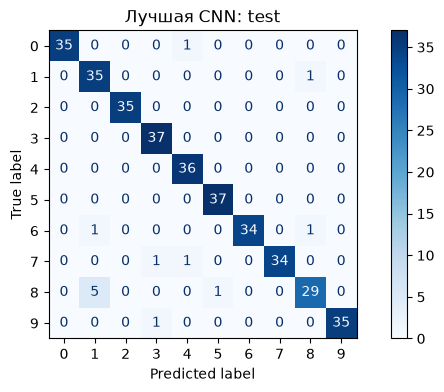

In [18]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
pred = np.argmax(best_model(X_test, training=False).numpy(), axis=1)
print(classification_report(y_test, pred, digits=3))
ConfusionMatrixDisplay.from_predictions(y_test, pred, cmap='Blues')
plt.title('Лучшая CNN: test'); plt.show()


**Наблюдения сохранённого запуска.** Требуемая CNN получила 94,72% val после одной эпохи. За 10 эпох CustomConvNet с Adam 0.001 достигла 94,44% val, с Adam 0.003 — 97,22%, с BN/dropout/L2 — 96,39%. На этих данных больший шаг ускорил обучение; совместная регуляризация лучшую val не улучшила. Выбрана Adam 0.003: test 96,39%. Последняя val этой модели (95,28%) ниже лучшей, поэтому сохранение лучшей эпохи полезно.
